# ML Assignment 2 – Online Shoppers Purchase Intention

**Dataset:** Online Shoppers Purchasing Intention (UCI, id 468) · **Task:** binary classification (`Revenue`: did the session end in a purchase?)


## 1. Imports and setup

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
os.makedirs("model", exist_ok=True)

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__, "| numpy:", np.__version__)

scikit-learn: 1.9.1
pandas: 3.0.5 | numpy: 2.5.2


## 2. Load the dataset

In [3]:
DATA_PATH = "online_shoppers_intention.csv"

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    # Fallback: download straight from UCI (needs internet + `pip install ucimlrepo`)
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=468)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    df.to_csv(DATA_PATH, index=False)

print("Shape:", df.shape)   # expect (12330, 18): 17 features + Revenue
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Quick exploration

In [4]:
print(df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("Total missing:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.describe().T

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object 

Missing values per column:
 Series([], dtype: int64)
Total missing: 0
Duplicate rows: 125


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.5 %
True     15.5 %
Name: count, dtype: str


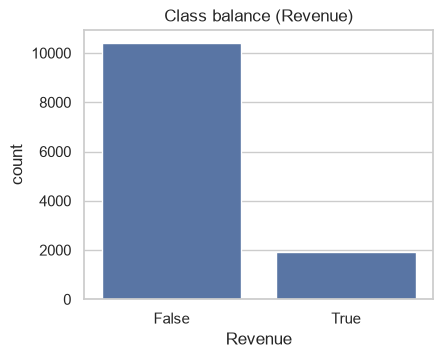

In [5]:
counts = df["Revenue"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x="Revenue", data=df, ax=ax)
ax.set_title("Class balance (Revenue)")
plt.show()

## 4. Preprocessing

- Convert `Revenue` (target) and `Weekend` from True/False to 1/0.
- `Month` and `VisitorType` are text, so they are **one-hot encoded**.
- All other columns are numeric and **standardized** (matters for Logistic Regression, KNN and SVM).

The encoding and scaling live **inside each saved pipeline**, so `test_data.csv` stays in the raw format and the Streamlit app can feed it straight to the model.

In [6]:
TARGET = "Revenue"
df[TARGET] = df[TARGET].astype(int)
df["Weekend"] = df["Weekend"].astype(int)

CAT_COLS = ["Month", "VisitorType"]
NUM_COLS = [c for c in df.columns if c not in CAT_COLS + [TARGET]]

X = df.drop(columns=TARGET)
y = df[TARGET]

print("Number of features:", X.shape[1])
print("Categorical:", CAT_COLS)
print("Numeric:", NUM_COLS)

Number of features: 17
Categorical: ['Month', 'VisitorType']
Numeric: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']


## 5. Train/test split and `test_data.csv`

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# This file goes into the GitHub repo and is what you upload in the Streamlit app.
# It contains ALL input features plus the target column.
test_df = pd.concat([X_test, y_test], axis=1)
test_df.to_csv("test_data.csv", index=False)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (9864, 17) | Test: (2466, 17)
Positive rate  train: 0.155 | test: 0.155


## 6. Define the five models

In [8]:
def make_preprocessor():
    # sparse_output=False keeps the matrix dense, which GaussianNB requires
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("num", StandardScaler(), NUM_COLS),
    ])

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes":         GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
}

# One full pipeline per model: preprocessing + classifier
pipelines = {name: Pipeline([("prep", make_preprocessor()), ("clf", clf)])
             for name, clf in classifiers.items()}

MODEL_FILES = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "KNN": "model/knn.joblib",
    "Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/svm.joblib",
}
list(pipelines)

['Logistic Regression',
 'Decision Tree',
 'KNN',
 'Naive Bayes',
 'Support Vector Machine']

## 7. Train, evaluate and save

In [9]:
def evaluate(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy":  accuracy_score(y_eval, pred),
        "AUC":       roc_auc_score(y_eval, proba),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall":    recall_score(y_eval, pred, zero_division=0),
        "F1":        f1_score(y_eval, pred, zero_division=0),
        "MCC":       matthews_corrcoef(y_eval, pred),
    }

rows, train_acc = [], {}
for name, pipe in pipelines.items():
    print(f"Training {name} ...")
    pipe.fit(X_train, y_train)
    joblib.dump(pipe, MODEL_FILES[name])
    rows.append({"ML Model Name": name, **evaluate(pipe, X_test, y_test)})
    train_acc[name] = accuracy_score(y_train, pipe.predict(X_train))

results = pd.DataFrame(rows).set_index("ML Model Name")
results.to_csv("model_comparison.csv")
print("\nDone. Saved models:", os.listdir("model"))

Training Logistic Regression ...
Training Decision Tree ...
Training KNN ...
Training Naive Bayes ...
Training Support Vector Machine ...

Done. Saved models: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'svm.joblib']


## 8. Comparison table 

In [10]:
display(results.round(4))
print("\nBest model per metric:")
print(results.idxmax())

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8812,0.8877,0.7432,0.3560,0.4814,0.4603
Decision Tree,0.8962,0.9090,0.7114,0.5550,0.6235,0.5702
KNN,0.8739,0.7993,0.6715,0.3639,0.4720,0.4322
Naive Bayes,0.6736,0.7939,0.2941,0.7906,0.4287,0.3249
Support Vector Machine,0.8861,0.8725,0.6996,0.4634,0.5575,0.5090



Best model per metric:
Accuracy           Decision Tree
AUC                Decision Tree
Precision    Logistic Regression
Recall               Naive Bayes
F1                 Decision Tree
MCC                Decision Tree
dtype: str


In [11]:
# Train vs test accuracy: a large gap means overfitting (useful for your observations)
gap = pd.DataFrame({
    "Train accuracy": pd.Series(train_acc),
    "Test accuracy": results["Accuracy"],
})
gap["Gap"] = gap["Train accuracy"] - gap["Test accuracy"]
display(gap.round(4))

,Train accuracy,Test accuracy,Gap
Logistic Regression,0.8855,0.8812,0.0044
Decision Tree,0.9171,0.8962,0.0209
KNN,0.8990,0.8739,0.0251
Naive Bayes,0.6846,0.6736,0.0111
Support Vector Machine,0.9089,0.8861,0.0228


## 9. Confusion matrices and ROC curves

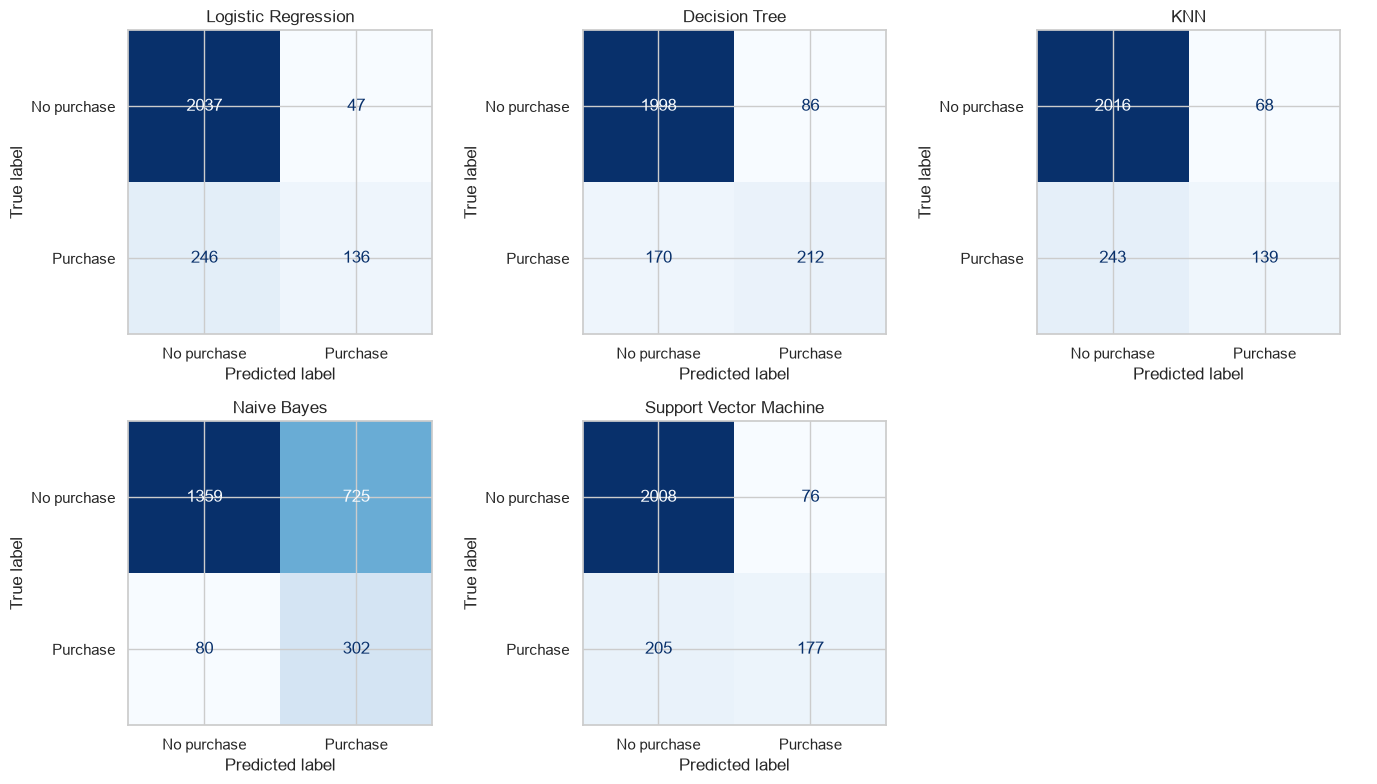

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["No purchase", "Purchase"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

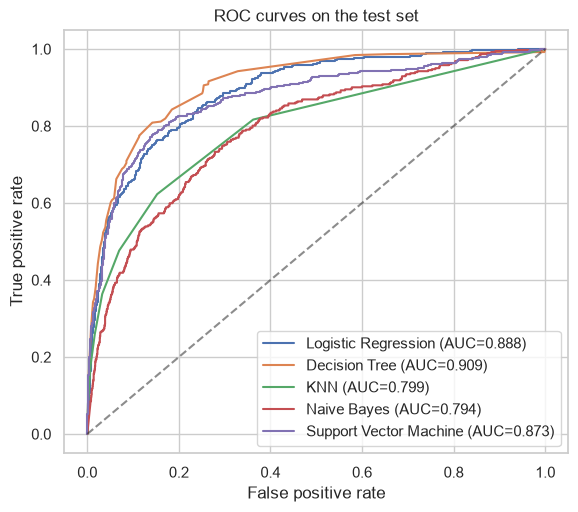

In [13]:
plt.figure(figsize=(6.5, 5.5))
for name, pipe in pipelines.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right")
plt.show()

In [14]:
# Per-class view: the minority "Purchase" class is where models really differ
for name, pipe in pipelines.items():
    print("=" * 60, "\n", name)
    print(classification_report(y_test, pipe.predict(X_test),
                                target_names=["No purchase", "Purchase"], digits=3))

 Logistic Regression
              precision    recall  f1-score   support

 No purchase      0.892     0.977     0.933      2084
    Purchase      0.743     0.356     0.481       382

    accuracy                          0.881      2466
   macro avg      0.818     0.667     0.707      2466
weighted avg      0.869     0.881     0.863      2466

 Decision Tree
              precision    recall  f1-score   support

 No purchase      0.922     0.959     0.940      2084
    Purchase      0.711     0.555     0.624       382

    accuracy                          0.896      2466
   macro avg      0.816     0.757     0.782      2466
weighted avg      0.889     0.896     0.891      2466

 KNN
              precision    recall  f1-score   support

 No purchase      0.892     0.967     0.928      2084
    Purchase      0.671     0.364     0.472       382

    accuracy                          0.874      2466
   macro avg      0.782     0.666     0.700      2466
weighted avg      0.858     0.874

## 10. Reload check

In [15]:
test_csv = pd.read_csv("test_data.csv")
Xt, yt = test_csv.drop(columns=TARGET), test_csv[TARGET]

check = {}
for name, path in MODEL_FILES.items():
    loaded = joblib.load(path)
    check[name] = evaluate(loaded, Xt, yt)["Accuracy"]

print(pd.Series(check).round(4))
assert np.allclose(pd.Series(check).values, results["Accuracy"].values), "Mismatch after reload!"
print("\nReloaded models reproduce the results.")

Logistic Regression       0.8812
Decision Tree             0.8962
KNN                       0.8739
Naive Bayes               0.6736
Support Vector Machine    0.8861
dtype: float64

Reloaded models reproduce the results.
